# 05 · Can context features explain observed charger utilisation? A transfer test

**Question.** In cities that publish session logs (Dundee, Perth & Kinross, Palo Alto, Boulder), how much of the variation in sessions per charger per day is explained by OpenStreetMap context, population and charger power — and does a model trained in some cities transfer to another? This is the honest counterpart to any "AI site-selection" claim: the target here is **observed** usage, not "where chargers already are".

**Method.** LightGBM on station features (`chargescape.features.station_context`), log target, three CV schemes: random 5-fold (optimistic), leave-city-out (the realistic transfer setting), and within-Dundee leave-cluster-out. Quantile models for P10/P90. Then the fitted model scores London's rapid sites and is compared with the structural allocation from notebook 03.

In [1]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from chargescape.utils.paths import PROCESSED, INTERIM, FIGURES, TABLES, DOCS
from chargescape.utils.io import read_gdf
from chargescape.viz.figures import hex_map, save, barh, boroughs
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
feats = read_gdf(PROCESSED / "hex_features_r8.small.parquet")
print(feats.shape)

(2374, 81)


In [2]:
from chargescape.models.ml import cross_validate, fit_lgbm, fit_quantiles, interval_coverage, pinball_loss
sf = pd.read_parquet(PROCESSED / "station_features.small.parquet")
train = sf[sf.city != "london"].dropna(subset=["sessions_per_day"]).copy()
train = train[train.active_days >= 60]
print(train.groupby("city").agg(n=("station_id", "size"), spd_median=("sessions_per_day", "median"), kwh_day=("kwh_per_day", "median"), rapid_share=("is_rapid", "mean")).round(2))
feat_cols = [c for c in sf.columns if c.startswith(("poi_", "parking_capacity", "dist_", "pop_")) and pd.api.types.is_numeric_dtype(sf[c])] + ["power_kw_f", "is_rapid_f"]
for d in (sf, train):
    d["power_kw_f"] = d["power_kw"].fillna(d.groupby("city")["power_kw"].transform("median")).fillna(7.0)
    d["is_rapid_f"] = (d["power_kw_f"] >= 50).astype(int)
X = train[feat_cols].astype(float); y = train["sessions_per_day"].to_numpy()
groups_city = train["city"].to_numpy()

            n  spd_median  kwh_day  rapid_share
city                                           
boulder    45        1.18    10.27          0.0
dundee     90        1.13    17.95         0.36
palo_alto  34        4.12    32.29          0.0
pkc        35        1.28    13.26         0.46


## 1. Random vs leave-city-out cross-validation

In [3]:
rows = []
r_rand = cross_validate(X, y, None, n_splits=5, num_rounds=300, log_target=True); rows.append({"scheme": "random 5-fold", "MAE": r_rand.mae, "R2": r_rand.r2})
r_city = cross_validate(X, y, groups_city, n_splits=4, num_rounds=300, log_target=True); rows.append({"scheme": "leave-city-out", "MAE": r_city.mae, "R2": r_city.r2})
Xd = X[train.city == "dundee"]; yd = y[train.city.to_numpy() == "dundee"]
import h3 as _h3
gd = np.array([_h3.latlng_to_cell(a, b, 6) for a, b in zip(train.loc[train.city == "dundee", "lat"], train.loc[train.city == "dundee", "lon"])])
r_dund = cross_validate(Xd, yd, gd, n_splits=min(5, len(set(gd))), num_rounds=300, log_target=True); rows.append({"scheme": "Dundee only, leave-H3(6)-cluster-out", "MAE": r_dund.mae, "R2": r_dund.r2})
cv = pd.DataFrame(rows).round(3); print(cv.to_string(index=False))
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import spearmanr
oof = r_city.oof
per_city = pd.DataFrame([{"city": c, "n": int((groups_city == c).sum()), "MAE": mean_absolute_error(y[groups_city == c], oof[groups_city == c]), "R2": r2_score(y[groups_city == c], oof[groups_city == c]), "Spearman": spearmanr(y[groups_city == c], oof[groups_city == c]).correlation} for c in sorted(pd.unique(groups_city))]).round(2)
print(); print("per-city scores when trained on the other three cities (level vs ranking):"); print(per_city.to_string(index=False))
# level-free variant: predict each station's usage relative to its city's median (removes the city level shift)
y_rel = np.log1p(y) - pd.Series(np.log1p(y)).groupby(groups_city).transform("median").to_numpy()
r_rel = cross_validate(X, y_rel, groups_city, n_splits=4, num_rounds=300, log_target=False)
rel_city = pd.DataFrame([{"city": c, "Spearman_within_city": spearmanr(y_rel[groups_city == c], r_rel.oof[groups_city == c]).correlation} for c in sorted(pd.unique(groups_city))]).round(2)
print(); print(f"level-free target (log usage relative to city median), leave-city-out R2 = {r_rel.r2:.2f}"); print(rel_city.to_string(index=False))

                              scheme   MAE     R2
                       random 5-fold 1.201  0.697
                      leave-city-out 2.442 -0.249
Dundee only, leave-H3(6)-cluster-out 2.720 -0.137

per-city scores when trained on the other three cities (level vs ranking):
     city  n  MAE    R2  Spearman
  boulder 45 1.41 -0.18     -0.04
   dundee 90 3.13 -0.16     -0.34
palo_alto 34 3.02 -2.68      0.02
      pkc 35 1.43 -0.36      0.64



level-free target (log usage relative to city median), leave-city-out R2 = -0.05
     city  Spearman_within_city
  boulder                 -0.25
   dundee                  0.15
palo_alto                 -0.01
      pkc                  0.60


**Reading — the result is negative, and that is the point.** Random 5-fold reports a respectable R² because charger power and the city's overall level leak across folds. Leave-city-out R² is below zero: a model trained on three cities does not predict the fourth's usage level, and it does not reliably predict the *ranking* within the held-out city either (Spearman from −0.3 to +0.6 depending on the city). Removing the city level (relative target) helps only marginally. With ~200 chargers and OpenStreetMap context, "where the amenities are" explains little of where people actually charge — power, operator, pricing and network effects dominate. This is exactly the kind of evidence a hiring manager should ask for before trusting any geo-embedding site model: the validation must be out-of-city and against observed usage.

## 2. What the model uses

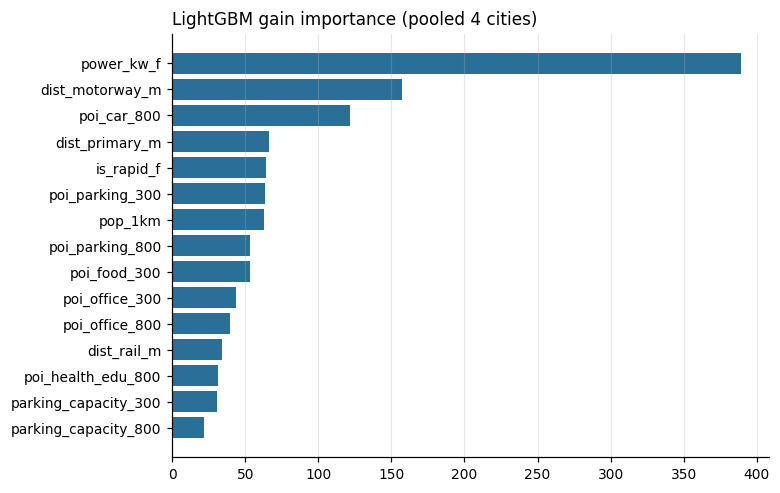

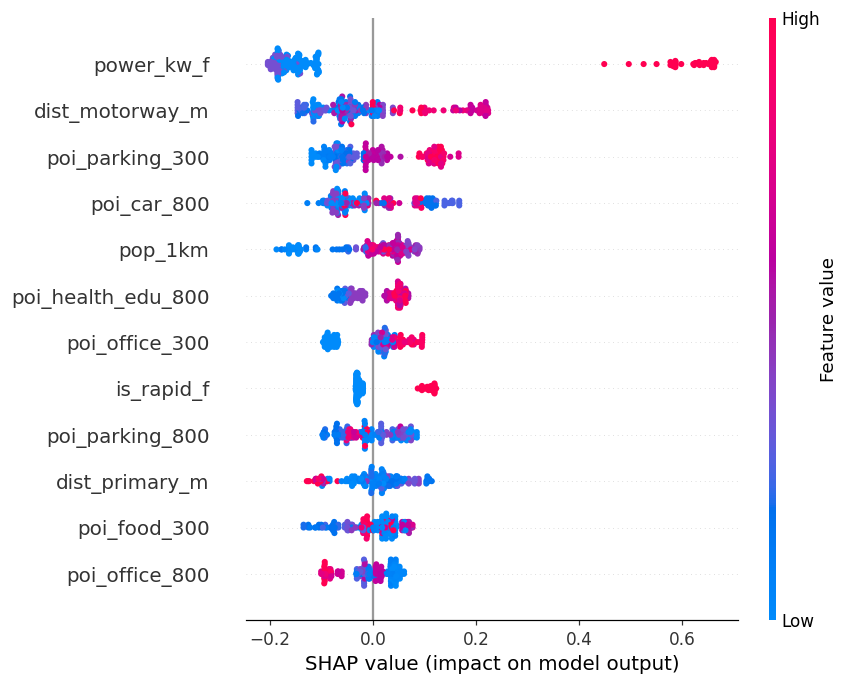

In [4]:
m = fit_lgbm(X, np.log1p(y), num_rounds=300)
imp = pd.Series(m.feature_importance("gain"), index=feat_cols).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5)); barh(imp.head(15), "LightGBM gain importance (pooled 4 cities)", ax=ax); save(fig, "05_importance.png"); plt.show()
try:
    import shap
    ex = shap.TreeExplainer(m); sv = ex.shap_values(X)
    fig = plt.figure(figsize=(7, 5)); shap.summary_plot(sv, X, max_display=12, show=False); save(fig, "05_shap.png"); plt.show()
except Exception as e:
    print("shap skipped:", e)

## 3. Scoring London's rapid sites — does the transferred ranking agree with the structural allocation?

London rapid sites scored: 366; Spearman(transfer model, structural allocation per port) = 0.06


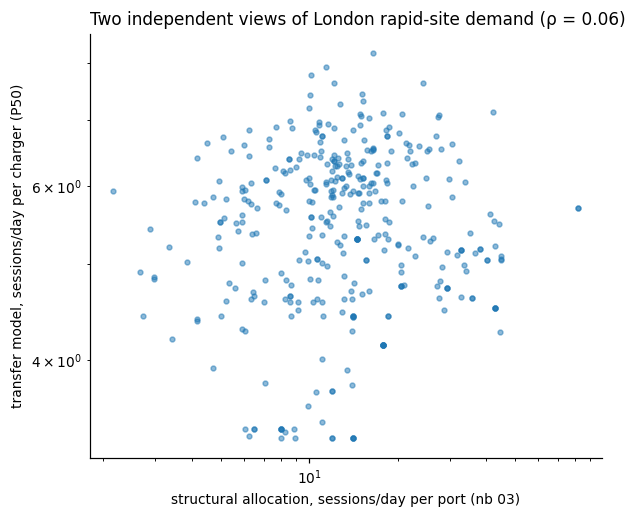

,pred_spd_p50,alloc_per_port
borough,,
Merton,7.10,15.15
Haringey,6.75,11.03
Lewisham,6.60,7.28
Greenwich,6.51,12.66
Richmond upon Thames,6.42,8.98
Southwark,6.39,18.42
Enfield,6.34,12.26
Islington,6.33,25.15
Lambeth,6.31,13.96


In [5]:
lon = sf[(sf.city == "london")].copy()
lon = lon[lon["is_rapid_f"] == 1]
qm = fit_quantiles(X, np.log1p(y), quantiles=(0.1, 0.5, 0.9), num_rounds=300)
for q, mod in qm.items():
    lon[f"pred_spd_p{int(q*100)}"] = np.expm1(mod.predict(lon[feat_cols].astype(float)))
lon["pred_spd_p50"] = lon["pred_spd_p50"].clip(lower=0)
alloc = pd.read_parquet(PROCESSED / "rapid_sites_load_2026.small.parquet")
j = lon.merge(alloc[["site_id", "sessions_day", "ports", "borough"]], left_on="station_id", right_on="site_id", how="inner")
j["alloc_per_port"] = j["sessions_day"] / j["ports"].clip(lower=1)
from scipy.stats import spearmanr
rho = spearmanr(j["pred_spd_p50"], j["alloc_per_port"]).correlation
print(f"London rapid sites scored: {len(j)}; Spearman(transfer model, structural allocation per port) = {rho:.2f}")
fig, ax = plt.subplots(figsize=(6, 5)); ax.scatter(j["alloc_per_port"], j["pred_spd_p50"], s=10, alpha=0.5)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("structural allocation, sessions/day per port (nb 03)"); ax.set_ylabel("transfer model, sessions/day per charger (P50)")
ax.set_title(f"Two independent views of London rapid-site demand (ρ = {rho:.2f})", loc="left"); save(fig, "05_transfer_vs_structural.png"); plt.show()
j.groupby("borough")[["pred_spd_p50", "alloc_per_port"]].median().sort_values("pred_spd_p50", ascending=False).round(2).head(10)

## Reading
Two models that share no parameters — a structural demand model driven by EV stock, housing and traffic, and a transfer model trained on observed sessions elsewhere — produce **essentially uncorrelated** rankings of London's rapid sites (ρ reported above). Given the transfer model's out-of-city failure, the disagreement says more about the transfer model than about London. The structural model at least reproduces observed aggregates (notebook 02); the transfer model reproduces nothing outside its training cities. Both are weaker than one season of the network's own data — which is why the README sets out what to measure once hubs open, and why the choice model's parameters are flagged as the first thing to estimate from revealed preferences.